# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [4]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE45719' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,Hvcn1,Gbp7,Arrdc1,Ercc5,Mrpl15,Dclk1,Tssc4,Gm101,Pum2,Erv3,...,0610043K17Rik,1700125G02Rik,4930465A12Rik,1700003M07Rik,Slc30a2,4930515B02Rik,1810035I16Rik,1700045H11Rik,Sox5,Alg11
cell_id,,,,,,,,,,,,,,,,,,,,,
GSM1112490,2,0,2246,1,2259,0,476,0,5144,0,...,0,0,0,0,0,0,0,0,0,9
GSM1112491,147,0,746,1,1614,0,708,0,3096,0,...,0,0,0,0,0,0,0,0,0,128
GSM1112492,0,0,1410,0,3969,0,517,0,4654,0,...,0,0,0,0,0,0,1,0,0,15
GSM1112493,103,0,727,0,3657,0,0,0,3337,0,...,0,0,0,0,0,0,0,0,0,94
GSM1112494,0,0,1682,132,5493,0,263,0,5213,0,...,0,0,0,0,17,0,7,0,0,69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM1278021,80,0,747,18,797,0,96,0,2207,0,...,10,0,0,0,31,0,0,0,0,0
GSM1278022,1,0,809,0,1048,0,282,0,1184,0,...,0,0,0,0,0,0,0,0,0,92
GSM1278023,148,0,411,116,1029,0,130,0,2021,0,...,0,0,0,0,90,0,0,0,0,193


## Dataset config

In [5]:
DATASET_DIR = DATASETS_DIR / 'GSE45719'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.05, min_gene_max_count=2, count_threshold=None, gene_threshold=None)

# Quality Control

In [6]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

None of the 37 mitochondrial genes (matched by name or Ensembl ID) were found in the data columns, so every cell's mitochondrial fraction is 0
None of the 356 rRNA genes (matched by name or Ensembl ID) were found in the data columns, so every cell's rRNA fraction is 0


count_depth           9234725.500
n_genes                  8621.500
mito_fraction               0.000
rrna_fraction               0.000
apoptosis_fraction          0.013
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
GSM1112662,61783010,13004,0.0,0.0,0.010
GSM1112656,57180786,14524,0.0,0.0,0.011
GSM1112663,52449255,14681,0.0,0.0,0.010
GSM1112654,45089018,14155,0.0,0.0,0.010
GSM1112657,43995933,12762,0.0,0.0,0.011


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
GSM1278020,1907676,8600,0.0,0.0,0.010
GSM1112556,1837237,8797,0.0,0.0,0.010
GSM1112677,1730604,5711,0.0,0.0,0.016
GSM1112557,1004461,8880,0.0,0.0,0.010
GSM1112746,384548,7018,0.0,0.0,0.011


None of the 37 mitochondrial genes (matched by name or Ensembl ID) were found in the data columns, so every cell's mitochondrial fraction is 0


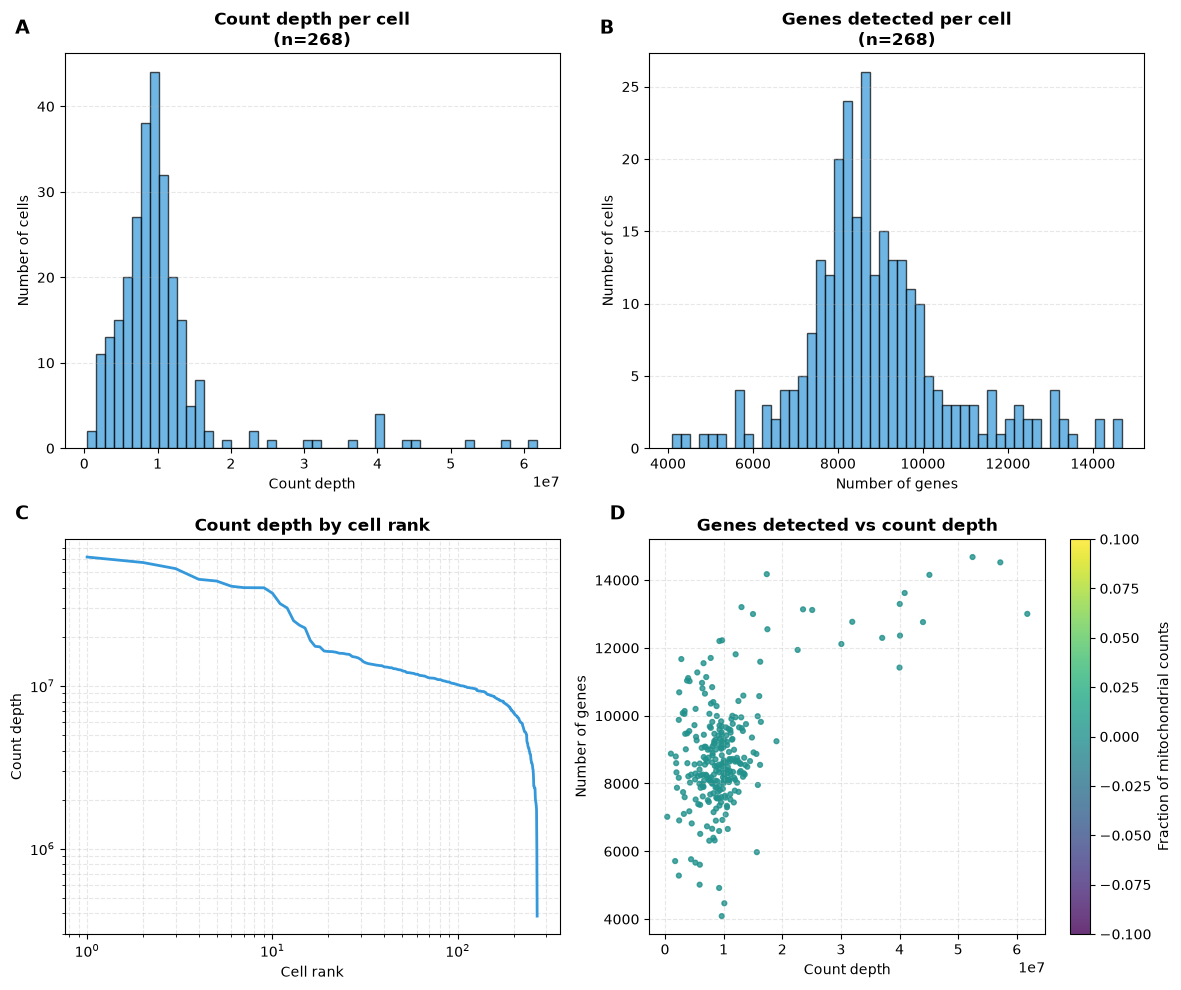

In [7]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    count_threshold=preprocessing_config.count_threshold,  # minimum count depth, set in the dataset config
    gene_threshold=preprocessing_config.gene_threshold,    # minimum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

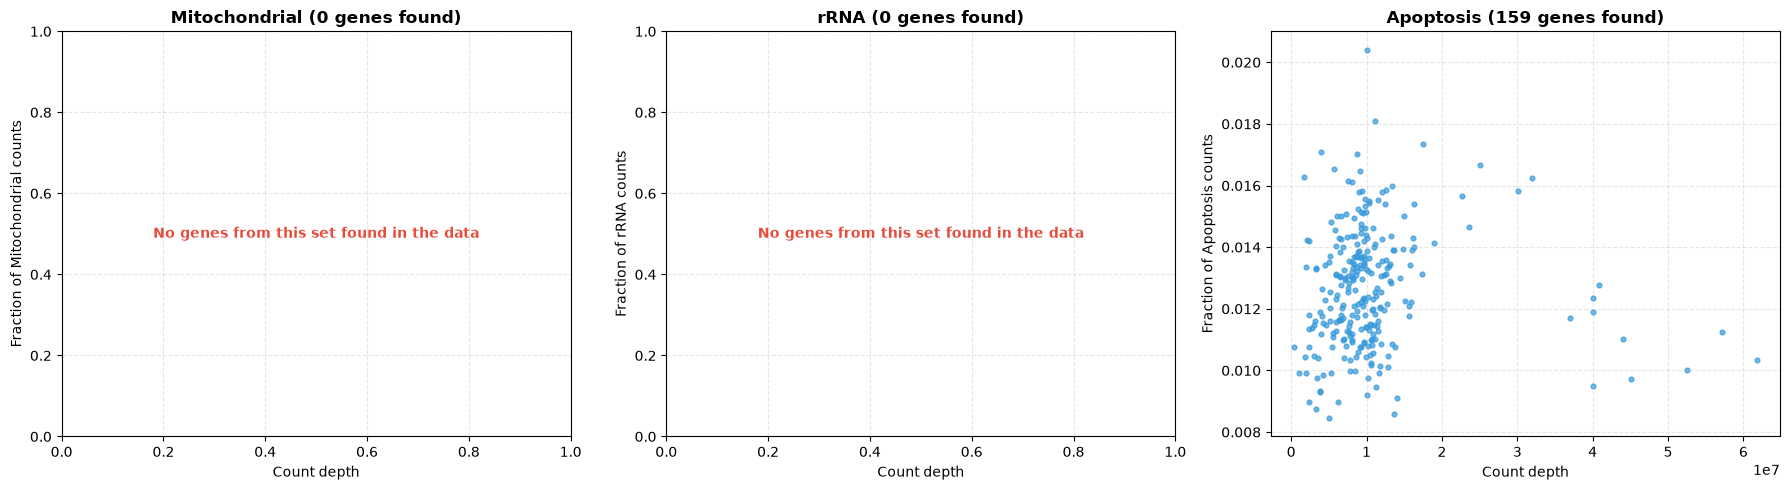

In [8]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [9]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 22431, unique gene names: 22431
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [10]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 4320 / 22431
  found through alias_names: 2 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 1, e.g. ['ENSMUSG00000068790']
  other: 4317, e.g. ['Gm101', 'Gm10922', 'Gm14347', 'AW549877', '6030422M02Rik']


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names
0,1700001J11Rik,1,ENSMUSG00000121668,Gm65991,protein_coding,9,NO_MT,NO_RB,NO_TF,NO_APOPT,1700001J11Rik
1,Dhrsx,1,ENSMUSG00000144291,NO_NAME,protein_coding,4,NO_MT,NO_RB,NO_TF,NO_APOPT,Dhrsx


### rRNA

In [11]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 0 / 22431
  share of all counts: 0.000


,total_counts


## Filtering pipeline

In [12]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

None of the 37 mitochondrial genes (matched by name or Ensembl ID) were found in the data columns, so every cell's mitochondrial fraction is 0


(268, 19879)

### Low expression genes

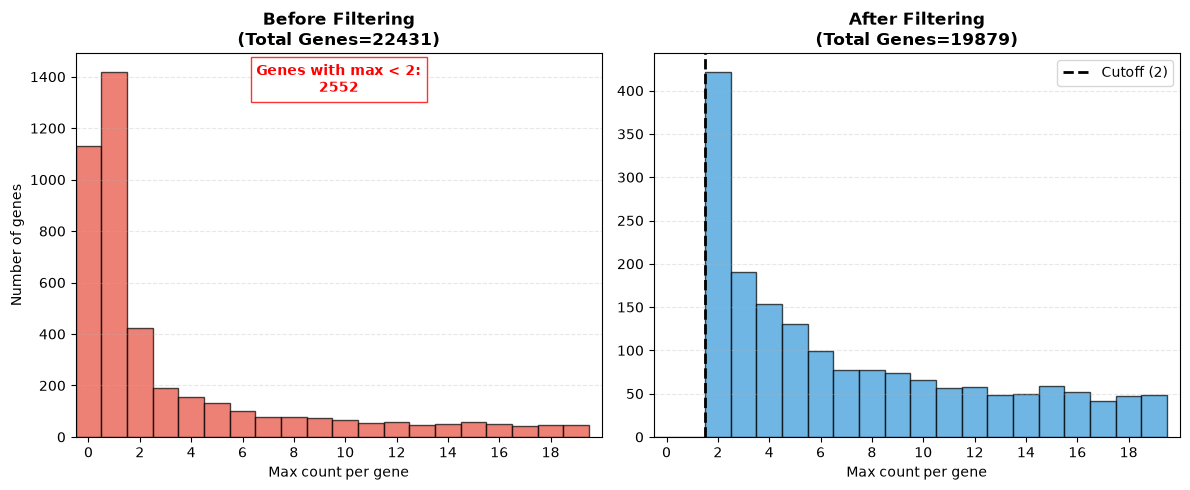

In [12]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

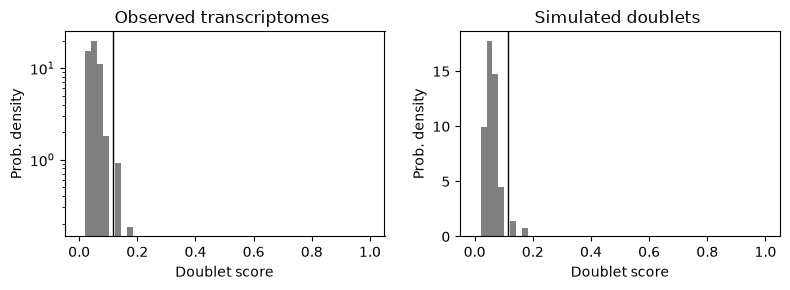

Cells removed as doublets: 6 / 268


In [13]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [14]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(268, 19879)

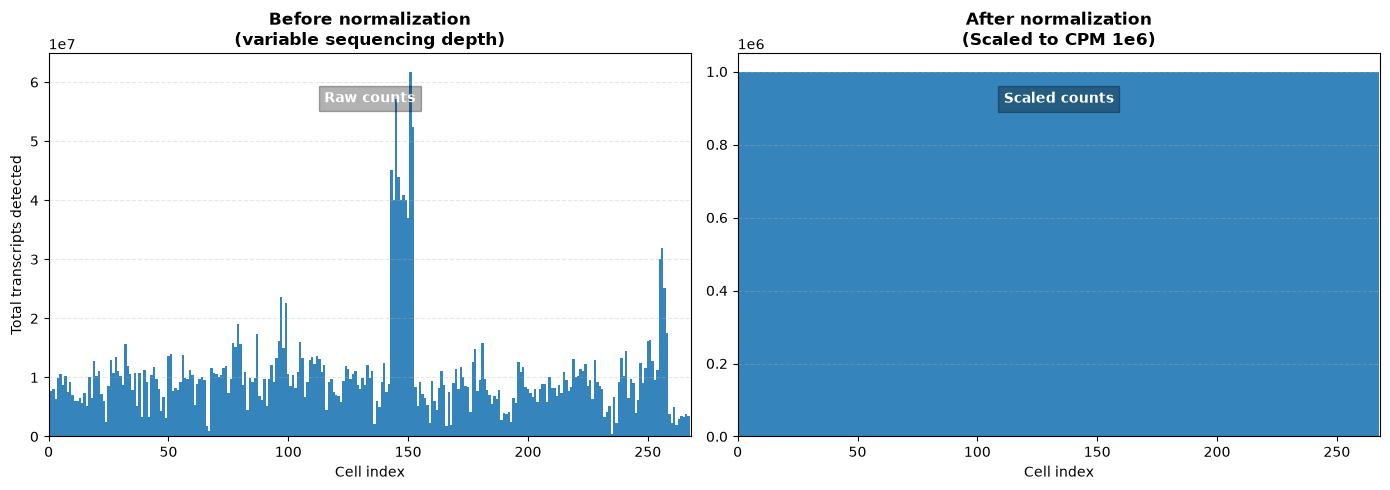

In [15]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [16]:
logged_data = log_transform(normalized_data)

logged_data.shape

(268, 19879)

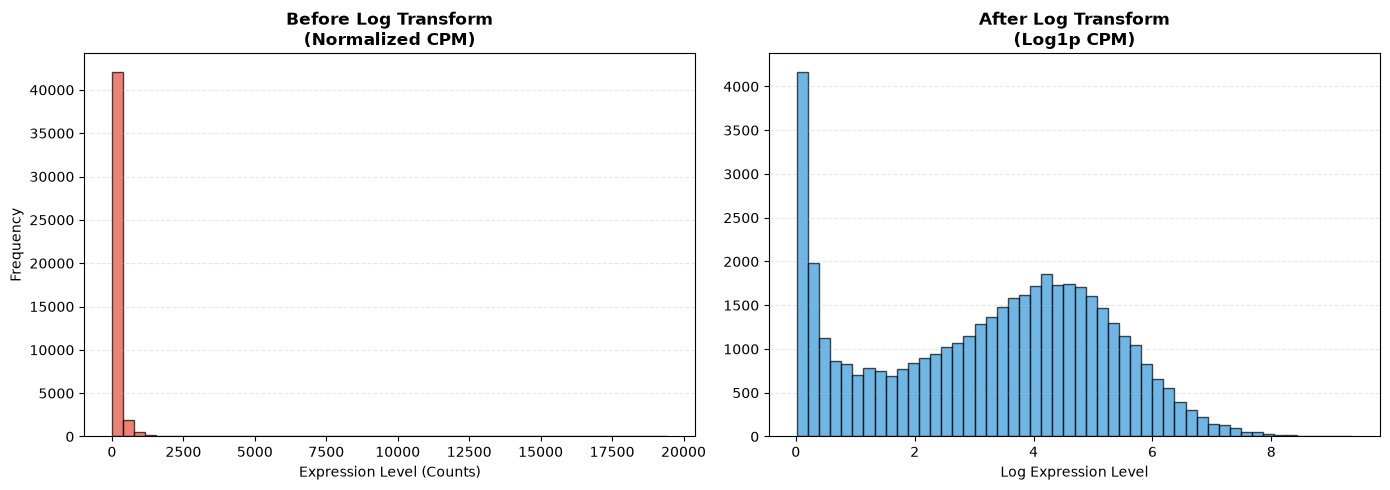

In [17]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [18]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(268, 19879)

In [19]:
pearsons_data.head()

,Hvcn1,Gbp7,Arrdc1,Ercc5,Mrpl15,Dclk1,Tssc4,Gm101,Pum2,Erv3,...,Gm13288,0610043K17Rik,1700125G02Rik,4930465A12Rik,1700003M07Rik,Slc30a2,4930515B02Rik,1810035I16Rik,Sox5,Alg11
cell_id,,,,,,,,,,,,,,,,,,,,,
GSM1112490,-8.242344,-6.030014,16.370706,-7.694473,0.395543,-0.673518,16.370706,-0.799286,1.308278,-0.765797,...,-0.124914,-2.068411,-0.382728,-0.079006,-1.580656,-7.902930,-0.096761,-1.461208,-1.445776,-8.094803
GSM1112491,-2.036687,-5.771432,3.779572,-7.474847,-1.458114,-0.629894,16.370706,-0.747603,-2.177027,-0.716257,...,-0.116791,-1.939115,-0.357870,-0.073868,-1.480184,-7.697646,-0.090469,-1.368015,-1.353529,-3.238626
GSM1112492,-8.199888,-5.859309,14.263647,-7.606093,9.736608,-0.644383,16.370706,-0.764770,1.181530,-0.732712,...,-0.119488,-1.982161,-0.366124,-0.075574,-1.513596,-7.768623,-0.092558,-0.698193,-1.384198,-7.732661
GSM1112493,-2.829120,-5.392879,6.094727,-7.200522,13.054462,-0.570974,-7.141782,-0.677771,0.229977,-0.649326,...,-0.105830,-1.763047,-0.324317,-0.066935,-1.343888,-7.377120,-0.081978,-1.241692,-1.228500,-3.641018
GSM1112494,-8.457532,-6.246975,13.859702,-1.698014,12.335240,-0.712635,4.868693,-0.845612,0.241439,-0.810209,...,-0.132204,-2.183531,-0.405031,-0.083617,-1.670408,-7.331062,-0.102408,2.879542,-1.528243,-6.362765
